# Balance between the activity and the pose-quality objective during training

The model is trained on the sum of two losses, L_total = L_activity + L_pose. Training uses one combined loader: every training step draws one activity and one pose mini-batch (32 complexes each) until the smaller pose loader is exhausted, after which the steps contain an activity mini-batch only. Both loaders are reshuffled every epoch, so every training complex of both datasets contributes once per epoch. Gradients are accumulated over four steps before each parameter update (effective batch size 128 per task).

Two questions:
1. **How many updates does each objective get?** From the training-set sizes (scaffold split, RMSD ≤ 10 Å).
2. **How strongly does each objective act on the shared network?** The number of updates alone does not say this. For the trained model of each fold and for the untrained model (initial weights), the gradients of L_activity and L_pose with respect to the shared parameters (all parameters except the final output layer, whose rows are task-specific) were computed on the first 400 training steps of an epoch, in the batch order of training (`gradient_balance.py`; it needs the trained checkpoints and a GPU, the results are in `data/gradient_balance/`).

Per step: the norms of the two gradients (overall and per block of the network), the cosine between them, and the share of the combined gradient that comes from the pose loss, g_pose · g / |g|², with g = g_activity + g_pose (the two shares add up to 1), on the raw gradient and after Adam's per-parameter scaling (trained model only, from the optimizer state saved with the model). Rows with `kind = batch` are single training steps, rows with `kind = optimizer_step` are sums over the four accumulated steps of one parameter update.

In [1]:
from pathlib import Path
import sys

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "kinodata" / "__init__.py").exists())
DATA = REPO / "analysis_publication" / "data" / "gradient_balance"
OUTPUT = REPO / "analysis_publication" / "output" / "gradient_balance"
OUTPUT.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(REPO / "analysis_publication"))
from plot_style import apply_style, COLORS
apply_style()

MODELS = {"untrained": ("Untrained", COLORS["neutral"]), "trained": ("Trained", COLORS["pose_aware"])}

## 1. Number of updates per objective

Batches per epoch from the training-set sizes (batch size 32, incomplete last batches dropped); optimizer steps = batches / 4 (gradient accumulation), rounded up.

In [2]:
counts = pd.read_csv(DATA / "update_counts.csv").set_index("fold")
ratio = counts["pose batches per epoch"] / counts["activity batches per epoch"]
print(f"pose batches per activity batch: {ratio.min():.3f}-{ratio.max():.3f}")
counts

pose batches per activity batch: 0.486-0.501


,activity training complexes,pose training poses,activity batches per epoch,pose batches per epoch,steps with both losses (%),optimizer steps per epoch,optimizer steps with the pose loss
fold,,,,,,,
0,96032,46624,3001,1457,48.6,751,365
1,95040,47616,2970,1488,50.1,743,372
2,95072,47584,2971,1487,50.1,743,372
3,95584,47040,2987,1470,49.2,747,368
4,95872,46752,2996,1461,48.8,749,366


## 2. Gradients of the two objectives on the shared parameters

Median over the 400 training steps (with both losses) per fold and model: ratio of the gradient norms |∇L_pose| / |∇L_activity|, cosine between the two gradients, and the pose share of the combined gradient.

In [3]:
grads = pd.concat([pd.read_csv(DATA / f"gradients_fold_{k}.csv.gz") for k in range(5)], ignore_index=True)
grads["ratio"] = grads["norm_pose"] / grads["norm_act"]

summary = (grads.groupby(["kind", "model", "fold"])
           .agg(epoch=("epoch", "first"), steps=("step", "size"), norm_ratio=("ratio", "median"), cosine=("cos", "median"),
                pose_share=("share_pose", "median"), pose_share_adam=("share_pose_adam", "median"))
           .rename(columns={"norm_ratio": "|∇L_pose| / |∇L_activity|", "pose_share": "pose share", "pose_share_adam": "pose share (Adam)"}))
summary.to_csv(OUTPUT / "gradient_summary_per_fold.csv")
summary.loc["batch"].round(3)

epoch  steps  |∇L_pose| / |∇L_activity|  cosine  pose share  \
model     fold                                                                
trained   0        55    400                      1.683   0.000       0.735   
          1        53    400                      1.690   0.032       0.741   
          2        47    400                      1.922   0.002       0.789   
          3        47    400                      1.795   0.003       0.767   
          4        54    400                      1.554   0.002       0.709   
untrained 0         0    400                      2.251  -0.003       0.833   
          1         0    400                      2.515   0.001       0.865   
          2         0    400                      2.469  -0.007       0.861   
          3         0    400                      2.583  -0.005       0.870   
          4         0    400                      2.430  -0.001       0.854   

                pose share (Adam)  
model     fold                     
trained   0                 0.731  
          1                 0.772  
          2                 0.776  
          3                 0.749  
          4                 0.692  
untrained 0                   NaN  
          1                   NaN  
          2                   NaN  
          3                   NaN  
          4                   NaN

Range over the five folds of the trained models, per training step and per parameter update (four accumulated steps):

In [4]:
rng = summary.xs("trained", level="model").groupby(level="kind")[["|∇L_pose| / |∇L_activity|", "cosine", "pose share", "pose share (Adam)"]].agg(["min", "max"])
rng.round(3)

|∇L_pose| / |∇L_activity|        cosine        pose share  \
                                     min    max    min    max        min   
kind                                                                       
batch                              1.554  1.922  0.000  0.032      0.709   
optimizer_step                     1.562  1.937 -0.007  0.055      0.707   

                      pose share (Adam)         
                  max               min    max  
kind                                            
batch           0.789             0.692  0.776  
optimizer_step  0.791             0.685  0.790

### Orthogonal gradients

A cosine near 0 means that the two gradients point in perpendicular directions of the parameter space: a step that follows one objective neither improves nor worsens the other to first order (cos > 0 would mean that the objectives help each other, cos < 0 that they conflict). For orthogonal gradients, |g|² = |g_activity|² + |g_pose|², so the pose share of the combined gradient is simply r² / (1 + r²) with r = |∇L_pose| / |∇L_activity|. In a network with about 1.9 million parameters, gradients of unrelated objectives are nearly orthogonal by default; the cosine shows that there is no systematic conflict or alignment between the two tasks.

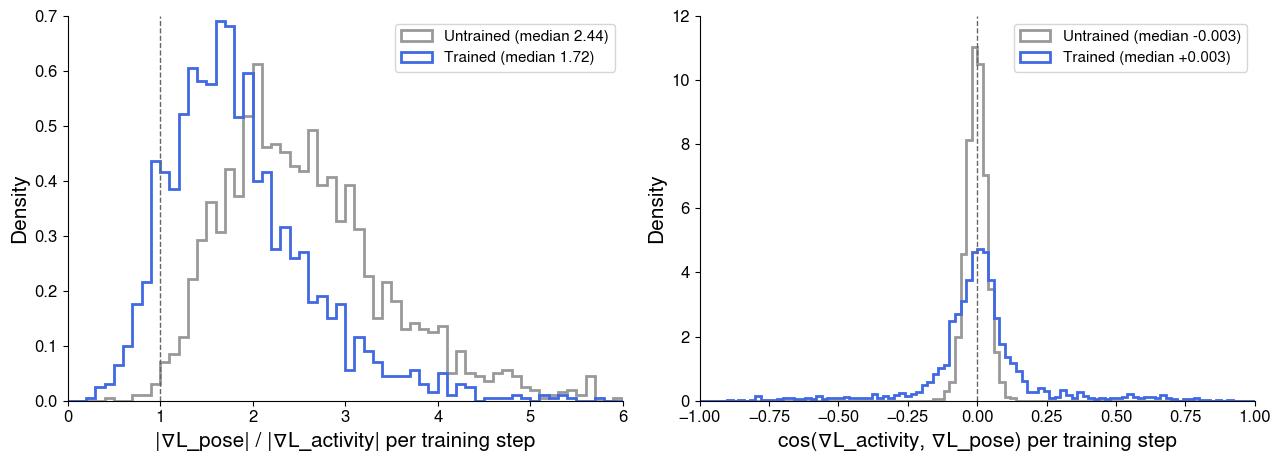

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
b = grads[grads.kind == "batch"]
for m, (name, col) in MODELS.items():
    g = b[b.model == m]
    axes[0].hist(g["ratio"], bins=np.arange(0, 6.01, 0.1), histtype="step", lw=2, color=col, density=True, label=f"{name} (median {g['ratio'].median():.2f})")
    axes[1].hist(g["cos"], bins=np.arange(-1, 1.001, 0.02), histtype="step", lw=2, color=col, density=True, label=f"{name} (median {g['cos'].median():+.3f})")
axes[0].axvline(1, color="0.4", lw=1, ls="--")
axes[0].set(xlim=(0, 6), xlabel="|∇L_pose| / |∇L_activity| per training step", ylabel="Density")
axes[1].axvline(0, color="0.4", lw=1, ls="--")
axes[1].set(xlim=(-1, 1), xlabel="cos(∇L_activity, ∇L_pose) per training step", ylabel="Density")
for ax in axes:
    ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(OUTPUT / "gradient_ratio_cosine.png", dpi=600)
plt.show()

### Per block of the network

Median |∇L_pose| / |∇L_activity| of the trained models (folds pooled) for each block of the shared network: input embedding, the three attention blocks, the readout aggregation and the feed-forward output layers before the final linear layer.

In [6]:
blocks = [c.replace("norm_act__", "") for c in grads.columns if c.startswith("norm_act__")]
t = b[b.model == "trained"]
pd.DataFrame({"|∇L_pose| / |∇L_activity| (median)": [(t[f"norm_pose__{x}"] / t[f"norm_act__{x}"]).median() for x in blocks]},
             index=pd.Index(blocks, name="block")).round(2)

,|∇L_pose| / |∇L_activity| (median)
block,
aggr,1.47
attention_blocks.0,2.00
attention_blocks.1,1.75
attention_blocks.2,1.74
input_embedding,1.89
out,1.04


## 3. Share of the pose objective over a whole epoch

Only the first part of every epoch contains a pose mini-batch (fraction f of the steps, section 1). Over an epoch, the pose objective's share of the summed squared gradient norm is approximately f · E|∇L_pose|² / (f · E|∇L_pose|² + E|∇L_activity|²), using the gradients of the trained models and the fact that the two gradients are nearly orthogonal (the activity gradient of the activity-only steps is assumed to be of the same size as in the steps with both losses).

In [7]:
rows = []
for k, g in t.groupby("fold"):
    f = counts.loc[k, "pose batches per epoch"] / counts.loc[k, "activity batches per epoch"]
    p2, a2 = (g["norm_pose"] ** 2).mean(), (g["norm_act"] ** 2).mean()
    rows.append({"fold": k, "fraction of steps with the pose loss": f, "pose share per step with both losses": p2 / (p2 + a2),
                 "pose share over the epoch": f * p2 / (f * p2 + a2)})
epoch_share = pd.DataFrame(rows).set_index("fold")
epoch_share.to_csv(OUTPUT / "pose_share_per_epoch.csv")
epoch_share.round(3)

,fraction of steps with the pose loss,pose share per step with both losses,pose share over the epoch
fold,,,
0,0.486,0.734,0.573
1,0.501,0.749,0.599
2,0.501,0.792,0.656
3,0.492,0.777,0.632
4,0.488,0.690,0.521
